# Part 3 baseline (non-leading partner): Shreya Akotiya

The brief asks the partner who did not lead Part 3 to implement and run the complete pipeline, at least as a working
baseline. `part3_agents/simple_pipeline.py` calls the team's five agents (Planner → Vision → Prompt Engineering →
Image Generation → Critique) once each, in a straight line, with **no revise loop and no orchestration layer**.
This notebook runs it on one scenario of each type from `part3_agents/eval/scenarios.csv`.

**How to run:** Colab, Runtime → Change runtime type → **T4 GPU**. Colab secrets: `ANTHROPIC_API_KEY` and
`GITHUB_TOKEN`. Then Runtime → **Run all** (about 10–15 minutes, most of it downloading the models).

In [3]:
# Cell 1 - run information
import os, subprocess, sys, datetime, platform
REPO, REF, WORK = "sakotiya/data266-lab2-team32", "main", "/content/data266-lab2-team32"
from google.colab import userdata
os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
if not os.path.isdir(WORK):
    token = userdata.get("GITHUB_TOKEN")
    subprocess.run(["git", "clone", "-q", "-b", REF, f"https://{token}@github.com/{REPO}.git", WORK], check=True)
os.chdir(WORK); sys.path.insert(0, WORK)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
gpu = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
print("run by: Shreya Akotiya (Part 3 baseline, non-leading partner)")
print("date:", datetime.datetime.now().isoformat(timespec="minutes"), "| code:", REF, commit)
print("python:", platform.python_version(), "| GPU:", gpu or "NONE - switch the runtime to T4")

run by: Shreya Akotiya (Part 3 baseline, non-leading partner)
date: 2026-11-16T23:22 | code: main 4bd8bce
python: 3.13.16 | GPU: Tesla T4


In [4]:
!pip install -q -r requirements.txt
!pip uninstall -q -y torchao   # Colab's torchao 0.10 makes peft refuse to load the LoRA
os.environ["P3_LORA"] = "sakotiya/data266-team32-naruto-run2-lora-r32"   # same adapter as the team's Part 3 runs
from part3_agents.src import models
print({"vlm": models.VLM, "lora": models.LORA, "device": models.DEVICE})

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
ibis-framework 9.5.0 r

## Run the simple pipeline on 5 scenarios (one per type)

In [5]:
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from part3_agents.simple_pipeline import run_simple_pipeline

scen = pd.read_csv("part3_agents/eval/scenarios.csv")
picked = scen[scen.scenario_id.isin(["S01", "S04", "S07", "S10", "S15"])]
rows, outputs = [], {}
for _, r in picked.iterrows():
    print("=" * 70, f"\n{r.scenario_id} ({r.type}): {r.request}")
    try:
        res = run_simple_pipeline(f"part3_agents/test_images/{r.image}", r.request)
        err = ""
    except Exception as e:                    # the simple version has no failure handling; record it
        res, err = {}, f"{type(e).__name__}: {e}"
        print("  ERROR:", err)
    route = res.get("plan", {}).get("route")
    crit = res.get("critique", {})
    rows.append({"scenario_id": r.scenario_id, "type": r.type, "expected_route": r.expected_route,
                 "route": route, "route_correct": route == r.expected_route,
                 "critic_decision": crit.get("decision"), "clip_score": crit.get("clip_score"),
                 "seconds": round(res.get("seconds", float("nan")), 1), "message": res.get("message", err)[:120]})
    if res.get("final_image") is not None:
        outputs[r.scenario_id] = (r.image, res["final_image"])
results = pd.DataFrame(rows)
os.makedirs("part3_agents/metrics", exist_ok=True)
results.to_csv("part3_agents/metrics/simple_pipeline_results.csv", index=False)
results

S01 (caption_question): Describe this image and tell me what the sign says.
Agent 1: Planner...
  Route: caption
Agent 2: Vision...
  Caption: An upside-down red octagonal STOP sign on a metal pole stands at a sunny street ...
S04 (style_change): Turn this into a watercolor painting.
Agent 1: Planner...
  Route: style_change
Agent 2: Vision...
  Caption: A cozy bedroom with a blue quilted comforter, a wooden dresser with an oval mirr...
Agent 3: Prompt Writer...
  Prompt: watercolor painting of a cozy bedroom interior, blue quilted comforter on bed, w...
Agent 4: Image Maker...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

... (24 outputs left out)

pytorch_lora_weights.safetensors: downloading bytes:           |  0.00B            

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  Generated image: (512, 512)
Agent 5: Critic...
  Decision: revise, Score: 3/5

Completed in 19.1s
S15 (ambiguous_broken): Make this a watercolor.
Agent 1: Planner...
  Route: error
  Stopping: The image could not be read (OSError). Please upload a valid JPG or PNG file.


,scenario_id,type,expected_route,route,route_correct,critic_decision,clip_score,seconds,message
0,S01,caption_question,caption,caption,True,None,NaN,12.4,This is a sunny street corner with a red octag...
1,S04,style_change,style_change,style_change,True,revise,29.32,110.9,Generated but could be improved: Keep the orig...
2,S07,edit,edit,edit,True,accept,32.89,82.2,Image generated successfully.
3,S10,domain_style,domain_style,domain_style,True,revise,36.56,19.1,Generated but could be improved: Keep the Naru...
4,S15,ambiguous_broken,error,error,True,None,NaN,0.0,The image could not be read (OSError). Please ...


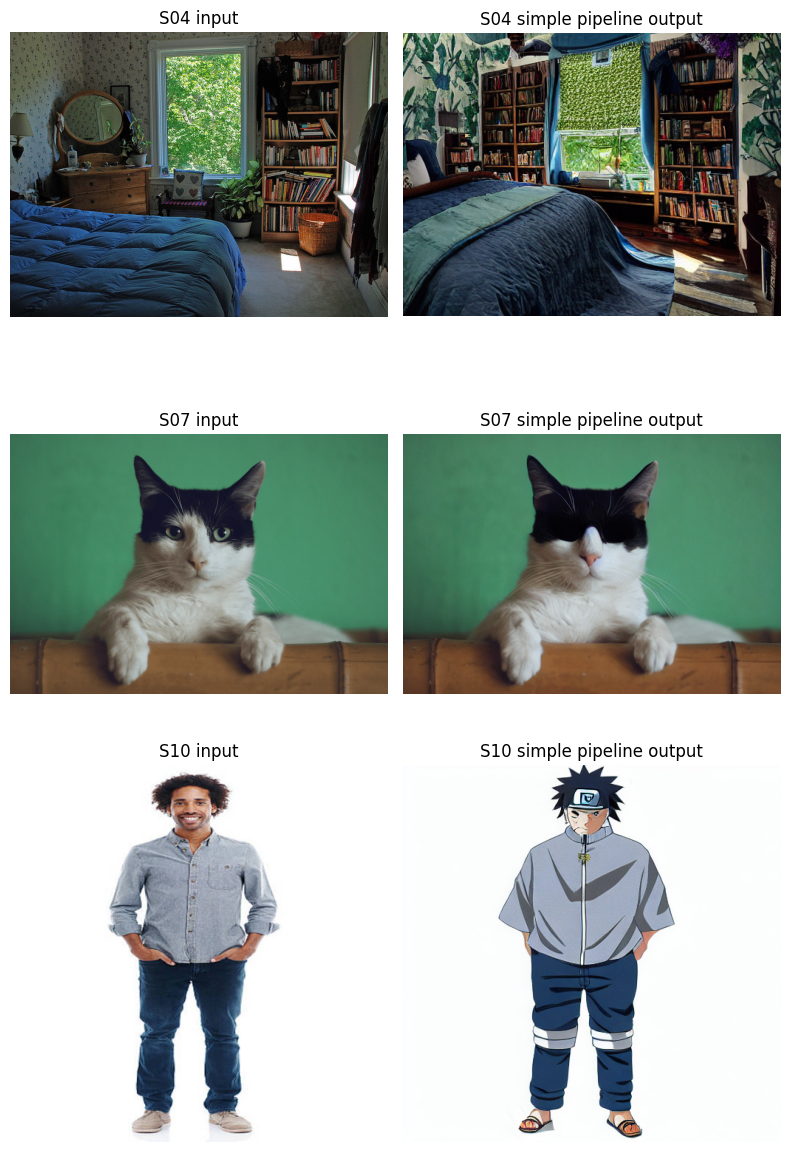

routes correct: 5 / 5 | median s/request: 19.1


In [6]:
fig, axes = plt.subplots(len(outputs), 2, figsize=(8, 4 * len(outputs)), squeeze=False)
for row, (sid, (src, out)) in enumerate(outputs.items()):
    axes[row, 0].imshow(Image.open(f"part3_agents/test_images/{src}")); axes[row, 0].set_title(f"{sid} input")
    axes[row, 1].imshow(out); axes[row, 1].set_title(f"{sid} simple pipeline output")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout(); plt.show()
print("routes correct:", int(results.route_correct.sum()), "/", len(results),
      "| median s/request:", results.seconds.median())

## Compared with the team's final system
The simple version shows the five agents working in order. What it does not have, and the team's `pipeline.run`
adds: the revise loop (at most 2 revisions with critic feedback and strength adjustment), one JSON trace per request,
and failure handling that turns an exception in any agent into a clear message.

Save: File → Download → `.ipynb`, and download `part3_agents/metrics/simple_pipeline_results.csv` from the file panel.